In [1]:
import pysam
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, Patch, FancyArrowPatch


In [2]:
# Approximate breakpoint windows from prior evidence (e.g. SNP array, short reads)
BP1_window = (322350, 326500)   # left breakpoint
BP2_window = (423500, 426000)   # right breakpoint
full_window = (250000, 500000)
#full_window = (362000, 365000)

chrom = 'CM083880.1'

In [3]:
bamfile = "../../../../hybrid_diversity/4_read_mapping/4_hifi_reads/map-hifi/UTEX2797_hifi_v12B1_K19_filtered_q20.bam"
aimsfile = '../../../../hybrid_diversity/4_read_mapping/4_hifi_reads/AIMfiles/AllAims_v2.tsv'
COLOR_MAP = {'A1': '#BB5566', 'A2': '#004488'}

In [4]:
bam = pysam.AlignmentFile(bamfile, "rb")

In [5]:
def get_breakpoint_reads(bam, chrom, bp_start, bp_end, min_flank=0):
    """
    Get reads that overlap the breakpoint window AND
    extend meaningfully into BOTH sides of it.
    """
    reads = []
    for read in bam.fetch(chrom, bp_start, bp_end):
        # Read must extend into the flank side AND the tract side
        extends_left  = read.reference_start < bp_start - min_flank
        extends_right = read.reference_end   > bp_end   + min_flank
        
        if extends_left and extends_right:  # overlaps window + has flank
            reads.append(read)
    return reads


In [6]:
def get_clipping(read):
    """
    Returns (left_clip, right_clip) for a pysam AlignedSegment.
    Handles both soft clip (op 4) and hard clip (op 5).
    """
    if read.cigartuples is None:
        return 0, 0

    left_clip  = 0
    right_clip = 0

    first_op, first_len = read.cigartuples[0]
    last_op,  last_len  = read.cigartuples[-1]

    if first_op in (4, 5):   # 4 = CSOFT_CLIP, 5 = CHARD_CLIP
        left_clip = first_len

    if last_op in (4, 5):
        right_clip = last_len

    return left_clip, right_clip


In [7]:
bp1_reads = get_breakpoint_reads(bam, chrom, * BP1_window)
bp2_reads = get_breakpoint_reads(bam, chrom, * BP2_window)

all_reads = []
for read in bam.fetch(chrom, full_window[0], full_window[1]):
    all_reads.append(read)

print(f"BP1 reads: {len(bp1_reads)}")
print(f"BP2 reads: {len(bp2_reads)}")
print(f"all reads: {len(all_reads)}")


BP1 reads: 10
BP2 reads: 13
all reads: 918


In [8]:
def genotype_read_at_snps_fast(read, snps_dict, chrom):
    """
    snps_dict: {chrom: {pos: {'A1': allele1, 'A2': allele2}, ...}, ...}
    """
    if chrom not in snps_dict:
        return []
    
    ref_to_query = {ref_pos: qpos
                    for qpos, ref_pos in read.get_aligned_pairs()
                    if qpos is not None and ref_pos is not None}
    calls = []
    
    # Only check positions that exist in ref_to_query
    for ref_pos, qpos in ref_to_query.items():
        if ref_pos in snps_dict[chrom]:
            snp = snps_dict[chrom][ref_pos]
            base = read.query_sequence[qpos]
            if base == snp['A1']:
                calls.append((ref_pos + 1, "A1"))  # +1 for 1-based output
            elif base == snp['A2']:
                calls.append((ref_pos + 1, "A2"))
    
    leftclip, rightclip = get_clipping(read)[0], get_clipping(read)[1]
    calls = sorted(calls)
    calls.append((read.query_name, read.reference_start, read.reference_end, leftclip, rightclip))
    return calls



In [9]:
# Build snp dictionary
snps_df = pd.read_csv(aimsfile, sep="\t")
snps_dict = {}
for chrom_name in snps_df["CHROM"].unique():
    snps_dict[chrom_name] = {}
    chrom_snps = snps_df[snps_df["CHROM"] == chrom_name]
    for _, row in chrom_snps.iterrows():
        pos = row["POS"] - 1  # 0-based
        snps_dict[chrom_name][pos] = {'A1': row['A1_ALLELE'], 'A2': row['A2_ALLELE']}


In [10]:
# Classify BP1 reads (expect A2 [flank] -> A1 [tract])
min_aims = 1

readsbp1 = []
for read in bp1_reads:
    calls = genotype_read_at_snps_fast(read, snps_dict, chrom)
    if len(calls) > min_aims:
        readsbp1.append(calls)    

readsbp2 = []
for read in bp2_reads:
    calls = genotype_read_at_snps_fast(read, snps_dict, chrom)
    if len(calls) > min_aims:
        readsbp2.append(calls)

readsall = []
for read in all_reads:
    calls = genotype_read_at_snps_fast(read, snps_dict, chrom)
    if len(calls) > min_aims:
        readsall.append(calls)


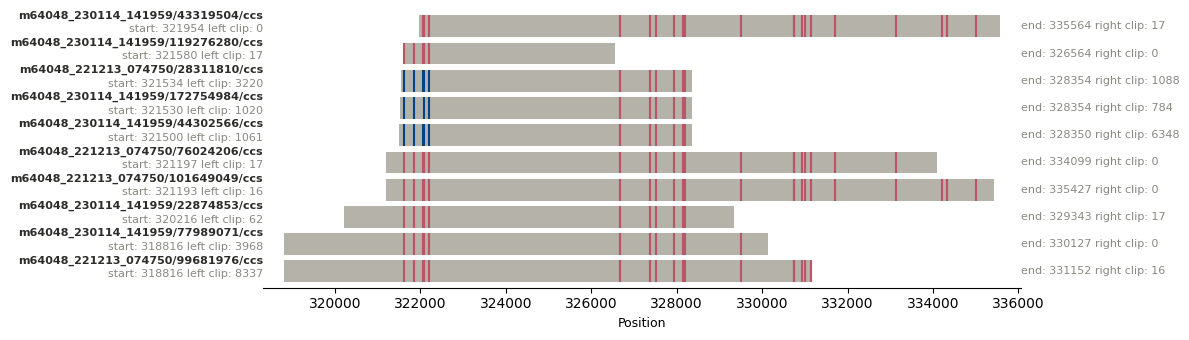

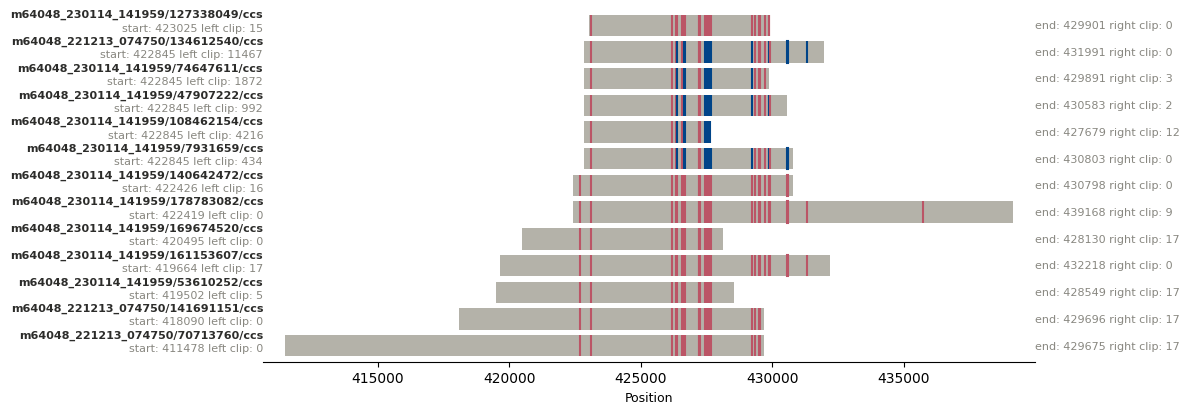

In [11]:
BAR_COLOR  = '#B4B2A9'
ROW_GAP    = 0.25
BAR_HEIGHT = 0.2
BOX_HEIGHT = 0.2
BOX_WIDTH  = 0.4
LEFT_PAD   = 2.5
RIGHT_PAD  = 1.5

def parse_read(read):
    """Extract metadata and SNP calls from a read."""
    name, start, end, leftclip, rightclip = read[-1]
    tuples = read[:-1]
    return name, start, end, tuples, leftclip, rightclip

def plot_reads(reads_data, title="Read Genotypes", filename=None, n_rows=None):
    """
    Plot genotyped reads with allele calls.
    
    Parameters:
    -----------
    reads_data : list
        Output from genotype_read_at_snps for multiple reads
    title : str
        Plot title
    filename : str, optional
        Save plot to this file
    n_rows : int, optional
        Number of rows to display (default: all reads)
    """
    if n_rows is None:
        n_rows = len(reads_data)
    else:
        reads_data = reads_data[:n_rows]
    
    # Calculate x-axis limits
    all_starts = [parse_read(r)[1] for r in reads_data]
    all_ends   = [parse_read(r)[2] for r in reads_data]
    x_min, x_max = min(all_starts), max(all_ends)
    x_pad = (x_max - x_min) * 0.03
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, len(reads_data) * ROW_GAP + 1.0))
    
    # Plot each read
    for row_i, read in enumerate(reads_data):
        name, start, end, tuples, leftclip, rightclip = parse_read(read)
        y = row_i * ROW_GAP
        
        # Gray bar spanning full read length
        ax.add_patch(mpatches.FancyBboxPatch(
            (start, y - BAR_HEIGHT / 2), end - start, BAR_HEIGHT,
            boxstyle="square,pad=0",
            linewidth=0, facecolor=BAR_COLOR,
        ))
        
        # Colored boxes at true positions
        for pos, allele in tuples:
            col = COLOR_MAP.get(allele, 'gray')
            ax.add_patch(mpatches.FancyBboxPatch(
                (pos - BOX_WIDTH, y - BOX_HEIGHT / 2), BOX_WIDTH * 2, BOX_HEIGHT,
                boxstyle="square,pad=0",
                linewidth=1.5, edgecolor=col, facecolor=col,
            ))
        
        # Left annotation: name + start
        ax.text(x_min - x_pad - LEFT_PAD * 0.3, y + 0.1, name,
                ha='right', va='center', fontsize=8, fontweight='bold',
                color='#2C2C2A', clip_on=False)
        ax.text(x_min - x_pad - LEFT_PAD * 0.3, y - 0.025, 
                f'start: {start} left clip: {leftclip}',
                ha='right', va='center', fontsize=8,
                color='#888780', clip_on=False)
        
        # Right annotation: end
        ax.text(x_max + x_pad + RIGHT_PAD * 0.3, y, 
                f'end: {end} right clip: {rightclip}',
                ha='left', va='center', fontsize=8,
                color='#888780', clip_on=False)
    
    # Configure axes
    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(-ROW_GAP * 0.6, (len(reads_data) - 1) * ROW_GAP + ROW_GAP * 0.6)
    ax.set_yticks([])
    ax.set_xlabel('Position', fontsize=9)
    ax.spines[['left', 'right', 'top']].set_visible(False)
    
    fig.tight_layout()
    plt.show()
    
    if filename:
        fig.savefig(filename)

# Usage:
plot_reads(readsbp1, filename="breakpoint1.pdf")
plot_reads(readsbp2, filename="breakpoint2.pdf")

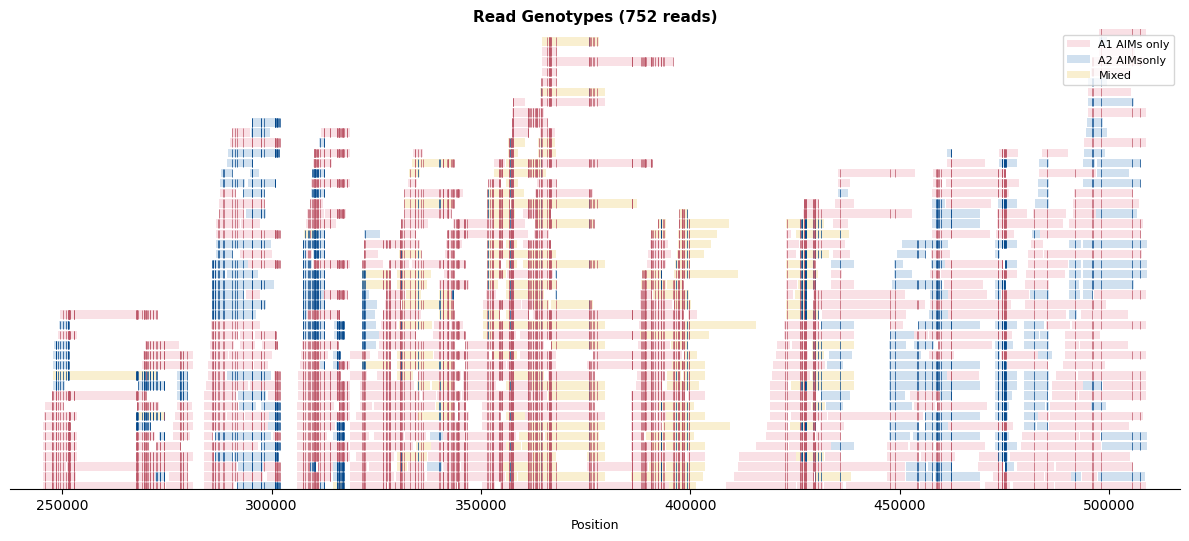

In [14]:
BAR_COLOR  = '#B4B2A9'
ROW_GAP    = 0.12
BAR_HEIGHT = 0.1
BOX_HEIGHT = 0.1
BOX_WIDTH  = 0.4

# Color scheme for read types
READ_TYPE_COLORS = {
    'A1_only': '#EE99AA',      
    'A2_only': '#6699CC',      
    'mixed': '#EECC66',        
}

def parse_read(read):
    """Extract metadata and SNP calls from a read."""
    name, start, end, leftclip, rightclip = read[-1]
    tuples = read[:-1]
    return name, start, end, tuples, leftclip, rightclip

def get_read_type(tuples):
    """Determine if read contains A1 only, A2 only, or mixed alleles."""
    if not tuples:
        return 'mixed'
    
    alleles = {allele for pos, allele in tuples}
    
    if alleles == {'A1'}:
        return 'A1_only'
    elif alleles == {'A2'}:
        return 'A2_only'
    else:
        return 'mixed'

def assign_rows(reads_data):
    """
    Assign reads to rows such that non-overlapping reads share a row.
    Returns list of (row_index, read) tuples.
    """
    # Extract start/end positions
    read_intervals = [(parse_read(r)[1], parse_read(r)[2]) for r in reads_data]
    
    # Track which reads are assigned to which rows
    rows = []  # List of lists, each sublist contains end positions of reads in that row
    read_rows = []  # List of row indices for each read
    
    for start, end in read_intervals:
        # Find a row where this read doesn't overlap with existing reads
        placed = False
        for row_idx, row_ends in enumerate(rows):
            # Check if this read overlaps with any read in this row
            if start >= max(row_ends):  # No overlap
                rows[row_idx].append(end)
                read_rows.append(row_idx)
                placed = True
                break
        
        # If no suitable row found, create a new one
        if not placed:
            rows.append([end])
            read_rows.append(len(rows) - 1)
    
    return read_rows, len(rows)

def plot_reads(reads_data, title="Read Genotypes", filename=None, n_rows=None):
    """
    Plot genotyped reads with allele calls, color-coded by read type.
    Non-overlapping reads share rows to minimize plot height.
    
    Parameters:
    -----------
    reads_data : list
        Output from genotype_read_at_snps for multiple reads
    title : str
        Plot title
    filename : str, optional
        Save plot to this file
    n_rows : int, optional
        Number of rows to display (default: all reads)
    """
    if n_rows is None:
        n_rows = len(reads_data)
    else:
        reads_data = reads_data[:n_rows]
    
    # Assign reads to rows
    read_rows, num_rows = assign_rows(reads_data)
    
    # Calculate x-axis limits
    all_starts = [parse_read(r)[1] for r in reads_data]
    all_ends   = [parse_read(r)[2] for r in reads_data]
    x_min, x_max = min(all_starts), max(all_ends)
    x_pad = (x_max - x_min) * 0.03
    
    # Create figure with height based on number of rows needed
    fig, ax = plt.subplots(figsize=(12, max(2, num_rows * ROW_GAP)))
    
    # Plot each read
    for read_idx, read in enumerate(reads_data):
        name, start, end, tuples, leftclip, rightclip = parse_read(read)
        y = read_rows[read_idx] * ROW_GAP
        
        # Determine read type and get background color
        read_type = get_read_type(tuples)
        bg_color = READ_TYPE_COLORS.get(read_type, '#B4B2A9')
        
        # Gray bar spanning full read length with type-specific background
        ax.add_patch(mpatches.FancyBboxPatch(
            (start, y - BAR_HEIGHT / 2), end - start, BAR_HEIGHT,
            boxstyle="square,pad=0",
            linewidth=0, facecolor=bg_color, alpha=0.3,
        ))
        
        # Colored boxes at true positions
        for pos, allele in tuples:
            col = COLOR_MAP.get(allele, 'gray')
            ax.add_patch(mpatches.FancyBboxPatch(
                (pos - BOX_WIDTH, y - BOX_HEIGHT / 2), BOX_WIDTH * 2, BOX_HEIGHT,
                boxstyle="square,pad=0",
                linewidth=0.5, edgecolor=col, facecolor=col,
            ))
    
    # Configure axes with no padding
    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(-ROW_GAP * 0.2, (num_rows - 1) * ROW_GAP + ROW_GAP * 0.2)
    ax.set_yticks([])
    ax.set_xlabel('Position', fontsize=9)
    ax.set_title(f"{title} ({len(reads_data)} reads)", fontsize=11, fontweight='bold')
    ax.spines[['left', 'right', 'top']].set_visible(False)
    
    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=READ_TYPE_COLORS['A1_only'], alpha=0.3, label='A1 AIMs only'),
        Patch(facecolor=READ_TYPE_COLORS['A2_only'], alpha=0.3, label='A2 AIMs only'),
        Patch(facecolor=READ_TYPE_COLORS['mixed'], alpha=0.3, label='Mixed'),
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=8)
    
    fig.tight_layout()
    plt.show()
    
    if filename:
        fig.savefig(filename)

                            
                            
plot_reads(readsall, filename="SV36_reads.pdf")